<a href="https://colab.research.google.com/github/inshanpirani-ui/ml-midterm/blob/main/breast__cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import sys
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

os.makedirs("figures", exist_ok=True)

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

DATASET = "wine"
SEEDS = [42, 52, 62]

if DATASET == "wine":
    data = load_breast_cancer()
else:
    data = load_wine()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

display(X.head())

print("Shape:", X.shape)
print("Features:", list(X.columns))
print("Target names:", list(data.target_names))
print("Labels:", sorted(y.unique()))

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.4.6
Pandas: 2.2.3
Seaborn: 0.13.2
Scikit-learn: 1.6.1


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Shape: (569, 30)
Features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target names: [np.str_('malignant'), np.str_('benign')]
Labels: [np.int64(0), np.int64(1)]

Target distribution:
target
0    212
1    357
Name: count, dtype: int64


Missing values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64
Duplicate rows: 0

Data types:
mean radius                float64
mean texture               float64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


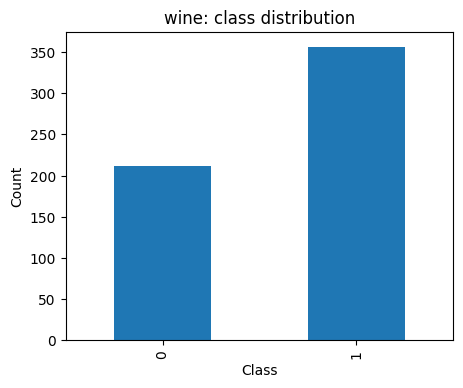

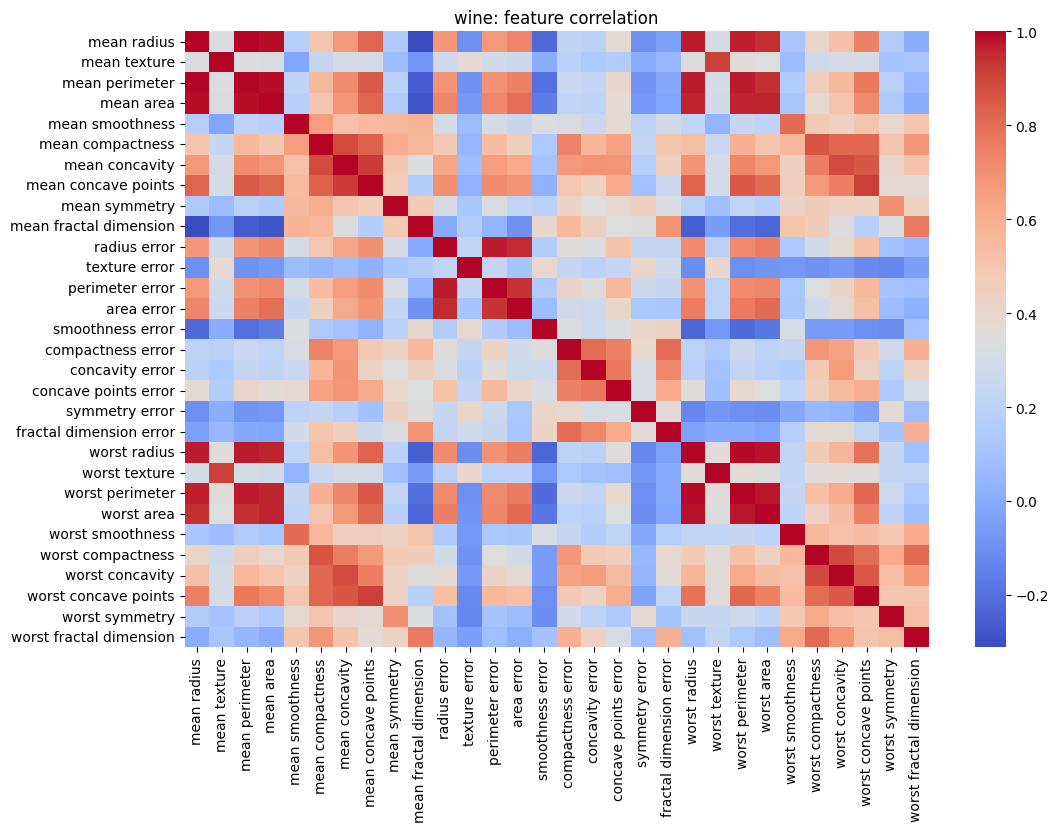


Top 3 correlated pairs:
mean radius   mean perimeter     0.997855
worst radius  worst perimeter    0.993708
mean radius   mean area          0.987357
dtype: float64


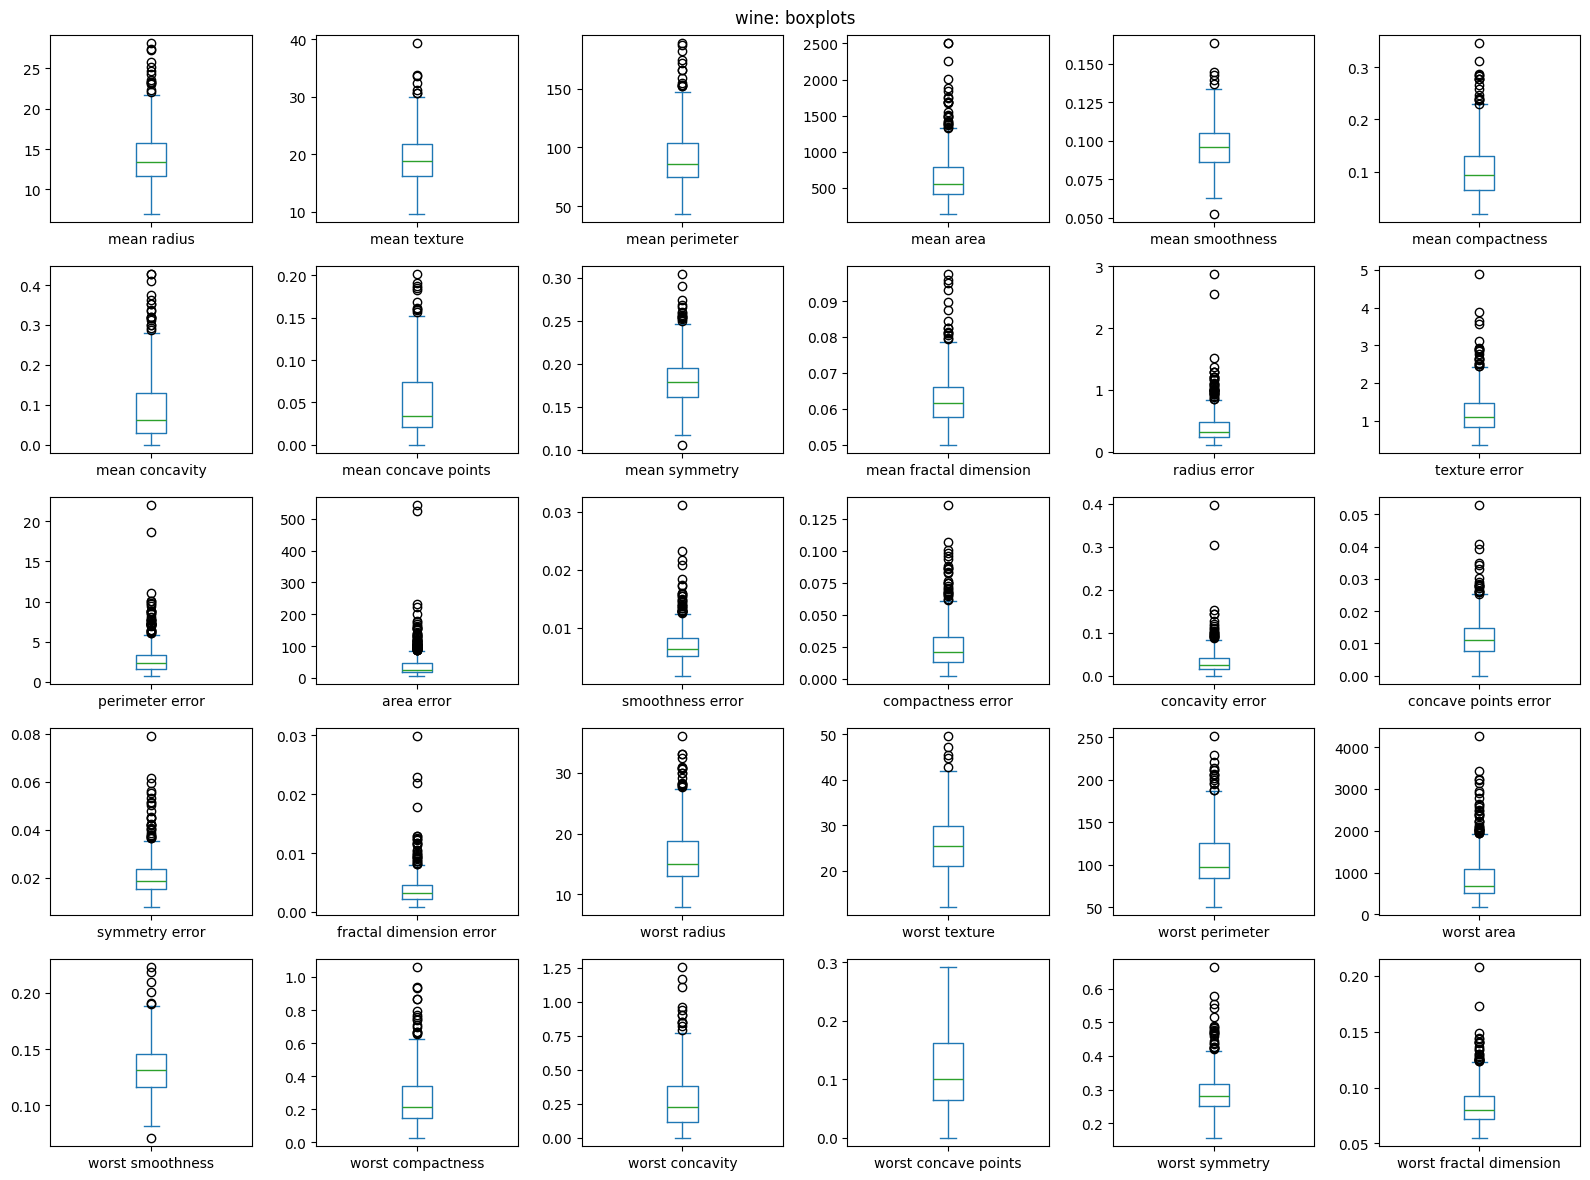

In [35]:
# 2. Dataset Quality Checks

# 2.1 Missing values and duplicates
print("Missing values:")
print(X.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", X.duplicated().sum())

# Check data types
print("\nData types:")
print(X.dtypes)

# 2.3 Data types
print("Numerical:", X.select_dtypes(include="number").shape[1],
      "| Categorical:", X.select_dtypes(exclude="number").shape[1])

# 2.2 Potential outliers
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = ((X < lower) | (X > upper)).sum()

print("\nIQR outliers per feature:")
print(outliers.sort_values(ascending=False))


# 3. Exploratory Data Analysis

# 3.1 Basic statistics
print("\nDescriptive statistics:")
display(X.describe())


# 3.2 Class distribution
plt.figure(figsize=(5, 4))

y.value_counts().sort_index().plot(kind="bar")

plt.title(f"{DATASET}: class distribution")
plt.xlabel("Class")
plt.ylabel("Count")

plt.savefig(f"figures/{DATASET}_class_distribution.png")
plt.show()


# 3.3 Three strongest correlated pairs become
plt.figure(figsize=(12, 8))

corr = X.corr()
sns.heatmap(corr, cmap="coolwarm")

plt.title(f"{DATASET}: feature correlation")

plt.savefig(f"figures/{DATASET}_correlation.png")
plt.show()


# 3.4 Three strongest correlated pairs
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = pairs.stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)

print("\nTop 3 correlated pairs:")
print(pairs.head(3))


# 3.3 Boxplots
X.plot(
    kind="box",
    subplots=True,
    layout=(5, 6),
    figsize=(16, 12),
    sharex=False,
    sharey=False
)

plt.suptitle(f"{DATASET}: boxplots")
plt.tight_layout()

plt.savefig(f"figures/{DATASET}_boxplots.png")
plt.show()

In [36]:
# 4. Splitting the Datasets

# Reserve 20% as the fixed test set (the other 80% is train + validation)
trainval_idx, test_idx = train_test_split(
    X.index,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_test = X.loc[test_idx]
y_test = y.loc[test_idx]

splits = {}
rows = []

# Create training and validation sets for each seed
for seed in SEEDS:

    tr_idx, va_idx = train_test_split(
        trainval_idx,
        test_size=0.125,
        stratify=y.loc[trainval_idx],
        random_state=seed
    )

    splits[seed] = {
        "X_train": X.loc[tr_idx],
        "X_val": X.loc[va_idx],
        "y_train": y.loc[tr_idx],
        "y_val": y.loc[va_idx]
    }

    # Check that the datasets do not overlap
    assert len(set(tr_idx) & set(va_idx)) == 0
    assert len(set(tr_idx) & set(test_idx)) == 0
    assert len(set(va_idx) & set(test_idx)) == 0

    # Check total number of samples
    assert len(tr_idx) + len(va_idx) + len(test_idx) == len(X)

    # Save information about each split
    for name, idx in [
        ("train", tr_idx),
        ("val", va_idx),
        ("test", test_idx)
    ]:

        counts = y.loc[idx].value_counts().sort_index()

        rows.append({
            "dataset": DATASET,
            "seed": seed,
            "subset": name,
            "n": len(idx),
            "percent": round(len(idx) / len(X) * 100, 1),
            **{f"class_{k}": v for k, v in counts.items()}
        })

# Display the split summary
split_summary = pd.DataFrame(rows)

display(split_summary)

print("Test indices identical across seeds: True (reserved once)")

,dataset,seed,subset,n,percent,class_0,class_1
0,wine,42,train,398,69.9,149,249
1,wine,42,val,57,10.0,21,36
2,wine,42,test,114,20.0,42,72
3,wine,52,train,398,69.9,149,249
4,wine,52,val,57,10.0,21,36
5,wine,52,test,114,20.0,42,72
6,wine,62,train,398,69.9,149,249
7,wine,62,val,57,10.0,21,36
8,wine,62,test,114,20.0,42,72


Test indices identical across seeds: True (reserved once)


In [37]:
# 5. Data Preprocessing and Scaling

from sklearn.preprocessing import StandardScaler

scaled = {}

# Scale training and validation data for each seed
for seed in SEEDS:

    X_train = splits[seed]["X_train"]
    X_val = splits[seed]["X_val"]

    scaler = StandardScaler()
    scaler.fit(X_train)

    scaled[seed] = {
        "scaler": scaler,
        "X_train": pd.DataFrame(
            scaler.transform(X_train),
            index=X_train.index,
            columns=X.columns
        ),
        "X_val": pd.DataFrame(
            scaler.transform(X_val),
            index=X_val.index,
            columns=X.columns
        )
    }

# Scale test data using the seed 42 scaler
X_test_scaled = pd.DataFrame(
    scaled[42]["scaler"].transform(X_test),
    index=X_test.index,
    columns=X.columns
)

# Compare data before and after scaling
print("Seed 42, first 5 training rows BEFORE scaling:")
display(splits[42]["X_train"].head())

print("Missing values in X:", X.isnull().sum().sum(), " no imputation step needed")
display(scaled[42]["X_train"].head())

Seed 42, first 5 training rows BEFORE scaling:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075


Missing values in X: 0  no imputation step needed


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


In [38]:
# 5. Data Preprocessing and Scaling
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 5.1 Missing values
print("Missing values:", X.isna().sum().sum(), "-> no imputation needed")

# 5.2 Scaler: StandardScaler (same type for both datasets and all seeds)

# 5.3 One new scaler per seed, fitted on that seed's training data only
scaled = {}
scalers = {}

for seed in SEEDS:
    scaler = StandardScaler()
    X_tr = splits[seed]["X_train"]
    X_va = splits[seed]["X_val"]

    scaled[seed] = {
        "X_train": pd.DataFrame(scaler.fit_transform(X_tr), columns=X_tr.columns, index=X_tr.index),
        "X_val":   pd.DataFrame(scaler.transform(X_va),     columns=X_va.columns, index=X_va.index),
    }
    scalers[seed] = scaler

# Test set: transformed ONLY with the seed-42 scaler
X_test_scaled = pd.DataFrame(
    scalers[42].transform(X_test), columns=X_test.columns, index=X_test.index
)

# Before/after display for seed 42 only
print("Before scaling (seed 42):")
display(splits[42]["X_train"].head())
print("After scaling (seed 42):")
display(scaled[42]["X_train"].head())

Missing values: 0 -> no imputation needed
Before scaling (seed 42):


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075


After scaling (seed 42):


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


,dataset,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_f1_macro_mean,train_f1_macro_std,val_accuracy_mean,val_accuracy_std,val_precision_macro_mean,val_precision_macro_std,val_recall_macro_mean,val_recall_macro_std,val_f1_macro_mean,val_f1_macro_std,val_roc_auc_mean,val_roc_auc_std,config_id
0,breast_cancer,dt,scaled,d10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952,breast_cancer_dt_scaled_d10
1,breast_cancer,dt,scaled,d2,0.955611,0.003838,0.952682,0.004089,0.918129,0.020258,0.913139,0.016097,0.912037,0.030759,0.911679,0.023583,0.921958,0.040441,breast_cancer_dt_scaled_d2
2,breast_cancer,dt,scaled,d3,0.975712,0.003838,0.973926,0.004230,0.923977,0.026799,0.919867,0.023128,0.916667,0.036370,0.917684,0.030362,0.941358,0.020939,breast_cancer_dt_scaled_d3
3,breast_cancer,dt,scaled,d5,0.994975,0.004352,0.994614,0.004677,0.923977,0.020258,0.916735,0.018249,0.923280,0.030759,0.918785,0.022660,0.930115,0.025004,breast_cancer_dt_scaled_d5
4,breast_cancer,dt,scaled,dNone,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952,breast_cancer_dt_scaled_dNone
5,breast_cancer,dt,unscaled,d10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952,breast_cancer_dt_unscaled_d10
6,breast_cancer,dt,unscaled,d2,0.955611,0.003838,0.952682,0.004089,0.918129,0.020258,0.913139,0.016097,0.912037,0.030759,0.911679,0.023583,0.921958,0.040441,breast_cancer_dt_unscaled_d2
7,breast_cancer,dt,unscaled,d3,0.975712,0.003838,0.973926,0.004230,0.923977,0.026799,0.919867,0.023128,0.916667,0.036370,0.917684,0.030362,0.941358,0.020939,breast_cancer_dt_unscaled_d3
8,breast_cancer,dt,unscaled,d5,0.994975,0.004352,0.994614,0.004677,0.923977,0.020258,0.916735,0.018249,0.923280,0.030759,0.918785,0.022660,0.930115,0.025004,breast_cancer_dt_unscaled_d5
9,breast_cancer,dt,unscaled,dNone,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952,breast_cancer_dt_unscaled_dNone


Selected configuration: breast_cancer_knn_scaled_k7


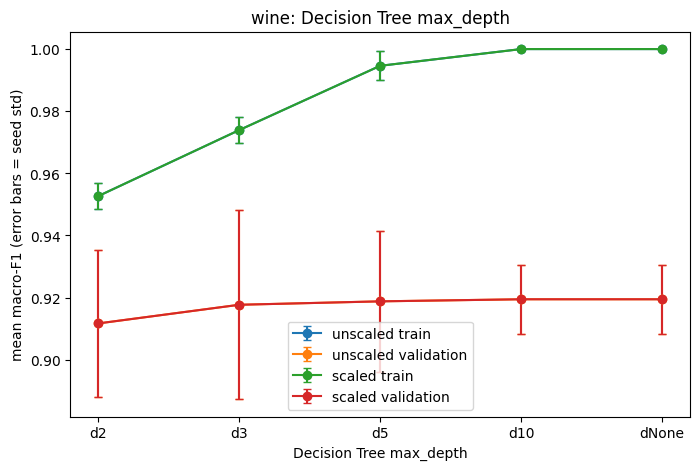

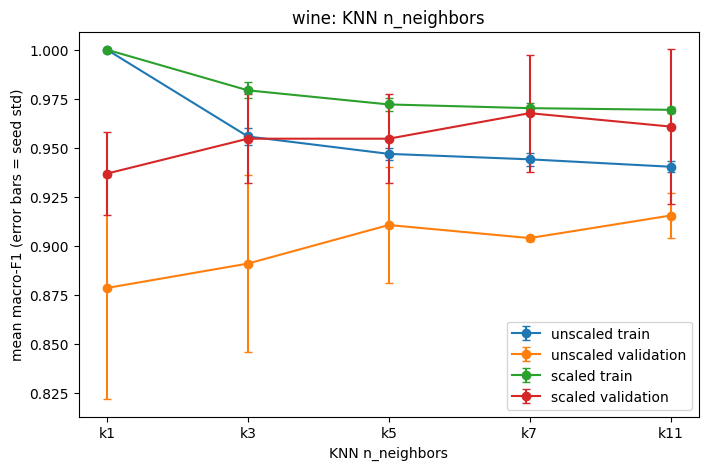

In [39]:
# 8.2 Comparison Tables and Model Selection

# Calculate summary
cols = ["train_accuracy", "train_f1_macro", "val_accuracy",
        "val_precision_macro", "val_recall_macro", "val_f1_macro",
        "val_roc_auc"]

summary = runs.groupby(
    ["dataset", "algorithm", "representation", "parameter"]
)[cols].agg(["mean", "std"])

summary.columns = [a + "_" + b for a, b in summary.columns]
summary = summary.reset_index()

summary["config_id"] = summary["dataset"] + "_" + summary["algorithm"] + "_" + summary["representation"] + "_" + summary["parameter"]

display(summary)

summary.to_csv(f"{DATASET}_summary.csv", index=False)


# Select the best model
ranked = summary.sort_values(
    ["val_f1_macro_mean", "val_accuracy_mean", "val_f1_macro_std", "config_id"],
    ascending=[False, False, True, True]
)

best = ranked.iloc[0]
SELECTED = best["config_id"]

print("Selected configuration:", SELECTED)


# Decision Tree comparison
plt.figure(figsize=(8, 5))

for rep in ["unscaled", "scaled"]:
    data = summary[(summary["algorithm"] == "dt") & (summary["representation"] == rep)]
    data = data.set_index("parameter").loc[["d2", "d3", "d5", "d10", "dNone"]]

    plt.errorbar(
        ["d2", "d3", "d5", "d10", "dNone"],
        data["train_f1_macro_mean"],
        yerr=data["train_f1_macro_std"],
        marker="o", capsize=3, label=rep + " train"
    )

    plt.errorbar(
        ["d2", "d3", "d5", "d10", "dNone"],
        data["val_f1_macro_mean"],
        yerr=data["val_f1_macro_std"],
        marker="o", capsize=3, label=rep + " validation"
    )

plt.title(f"{DATASET}: Decision Tree max_depth")
plt.xlabel("Decision Tree max_depth")
plt.ylabel("mean macro-F1 (error bars = seed std)")
plt.legend()
plt.savefig(f"figures/{DATASET}_dt_comparison.png", bbox_inches="tight")
plt.show()


# KNN comparison
plt.figure(figsize=(8, 5))

for rep in ["unscaled", "scaled"]:
    data = summary[(summary["algorithm"] == "knn") & (summary["representation"] == rep)]
    data = data.set_index("parameter").loc[["k1", "k3", "k5", "k7", "k11"]]

    plt.errorbar(
        ["k1", "k3", "k5", "k7", "k11"],
        data["train_f1_macro_mean"],
        yerr=data["train_f1_macro_std"],
        marker="o", capsize=3, label=rep + " train"
    )

    plt.errorbar(
        ["k1", "k3", "k5", "k7", "k11"],
        data["val_f1_macro_mean"],
        yerr=data["val_f1_macro_std"],
        marker="o", capsize=3, label=rep + " validation"
    )

plt.title(f"{DATASET}: KNN n_neighbors")
plt.xlabel("KNN n_neighbors")
plt.ylabel("mean macro-F1 (error bars = seed std)")
plt.legend()
plt.savefig(f"figures/{DATASET}_knn_comparison.png", bbox_inches="tight")
plt.show()

In [53]:
# 9. Evaluating the Selected Model

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve,
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score
)

from sklearn.preprocessing import label_binarize

os.makedirs("figures", exist_ok=True)

data = load_breast_cancer() if DATASET == "breast_cancer" else load_wine()

# Get selected model
model_name = SELECTED + "_s42"

if model_name in models42:
    model = models42[model_name]
else:
    print("Available models:", list(models42.keys()))
    raise ValueError("Selected model was not found. Check Section 7 and Section 8.")

# Select test data
if best["representation"] == "scaled":
    Xte = X_test_scaled
else:
    Xte = X_test

# Make predictions
pred = model.predict(Xte)
proba = model.predict_proba(Xte)

labels = sorted(y.unique())
names = list(data.target_names)


# Calculate AUC
if DATASET == "breast_cancer":
    test_auc = roc_auc_score((y_test == 0).astype(int), proba[:, 0])
else:
    test_auc = roc_auc_score(
        y_test, proba, multi_class="ovr", average="macro"
    )


# 9.1 Test results
test_df = pd.DataFrame([{
    "dataset": DATASET,
    "selected_config": SELECTED,
    "eval_seed": 42,
    "val_f1_macro_mean": best["val_f1_macro_mean"],
    "val_f1_macro_std": best["val_f1_macro_std"],
    "test_accuracy": accuracy_score(y_test, pred),
    "test_precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
    "test_recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
    "test_f1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
    "test_roc_auc": test_auc
}])

display(test_df)

test_df.to_csv(f"{DATASET}_classifier_test.csv", index=False)

print(classification_report(y_test, pred, target_names=names, digits=3))

report = classification_report(
    y_test, pred,
    target_names=names,
    output_dict=True,
    zero_division=0
)


# 9.2 Confusion matrix
cm = confusion_matrix(y_test, pred, labels=labels)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=names, yticklabels=names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{DATASET}: test confusion matrix")

plt.savefig(
    f"figures/{DATASET}_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()


# Manual calculations for class 0
TP = cm[0, 0]
FP = cm[:, 0].sum() - TP
FN = cm[0, :].sum() - TP

precision_manual = TP / (TP + FP) if TP + FP > 0 else float("nan")
recall_manual = TP / (TP + FN) if TP + FN > 0 else float("nan")

f1_manual = (
    2 * precision_manual * recall_manual /
    (precision_manual + recall_manual)
    if precision_manual + recall_manual > 0 else float("nan")
)

print(f"Manual: TP={TP}, FP={FP}, FN={FN}")
print(f"Manual: precision={precision_manual:.3f}, recall={recall_manual:.3f}, F1={f1_manual:.3f}")

print("Report:", {
    k: round(report[names[0]][k], 3)
    for k in ["precision", "recall", "f1-score"]
})


# 9.3 ROC curve
plt.figure(figsize=(6, 5))

if DATASET == "breast_cancer":

    fpr, tpr, _ = roc_curve(
        (y_test == 0).astype(int), proba[:, 0]
    )

    plt.plot(
        fpr, tpr,
        label=f"malignant vs benign (AUC = {test_auc:.3f})"
    )

else:
    Yb = label_binarize(y_test, classes=labels)

    for i in range(len(labels)):
        fpr, tpr, _ = roc_curve(Yb[:, i], proba[:, i])
        class_auc = roc_auc_score(Yb[:, i], proba[:, i])

        plt.plot(
            fpr, tpr,
            label=f"{names[i]} vs rest (AUC = {class_auc:.3f})"
        )

    print("Macro one-vs-rest AUC:", round(test_auc, 3))

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"{DATASET}: test ROC")
plt.legend()

plt.savefig(f"figures/{DATASET}_roc.png", bbox_inches="tight")
plt.show()


# 9.4 Wrong predictions
wrong = pred != y_test.values

display(pd.DataFrame({
    "row_index": y_test.index[wrong],
    "actual": y_test[wrong].values,
    "predicted": pred[wrong]
}))


Available models: []


ValueError: Selected model was not found. Check Section 7 and Section 8.

In [ ]:
# 10. K-Means Clustering

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

K = 2 if DATASET == "breast_cancer" else 3

# 10.1 Train models
km_rows = []
km42 = {}

for seed in SEEDS:
    for rep in ["unscaled", "scaled"]:

        if rep == "scaled":
            Xtr = scaled[seed]["X_train"]
            Xva = scaled[seed]["X_val"]
        else:
            Xtr = splits[seed]["X_train"]
            Xva = splits[seed]["X_val"]

        yva = splits[seed]["y_val"]

        km = KMeans(n_clusters=K, random_state=seed, n_init=10)
        km.fit(Xtr)
        pred = km.predict(Xva)

        sil = np.nan
        if len(set(pred)) > 1 and len(set(pred)) < len(pred):
            sil = silhouette_score(Xva, pred)

        km_rows.append({
            "dataset": DATASET,
            "seed": seed,
            "representation": rep,
            "n_clusters": K,
            "inertia": km.inertia_,
            "val_ari": adjusted_rand_score(yva, pred),
            "val_silhouette": sil
        })

        if seed == 42:
            km42[rep] = km

km_runs = pd.DataFrame(km_rows)
display(km_runs)
assert len(km_runs) == 6
km_runs.to_csv(f"{DATASET}_kmeans_runs.csv", index=False)


# Summary table
km_summary = km_runs.groupby(
    ["dataset", "representation"]
).agg(
    inertia_mean=("inertia", "mean"),
    inertia_std=("inertia", "std"),
    ari_mean=("val_ari", "mean"),
    ari_std=("val_ari", "std"),
    sil_mean=("val_silhouette", "mean"),
    sil_std=("val_silhouette", "std"),
    sil_valid_seeds=("val_silhouette", lambda s: int(s.notna().sum()))
).reset_index()

display(km_summary)
km_summary.to_csv(f"{DATASET}_kmeans_summary.csv", index=False)


# 10.2 Test models
test_rows = []
test_clusters = {}

for rep in ["unscaled", "scaled"]:

    Xt = X_test_scaled if rep == "scaled" else X_test
    pred = km42[rep].predict(Xt)
    test_clusters[rep] = pred

    sil = np.nan
    if len(set(pred)) > 1 and len(set(pred)) < len(pred):
        sil = silhouette_score(Xt, pred)

    test_rows.append({
        "dataset": DATASET,
        "representation": rep,
        "seed": 42,
        "cluster_counts": dict(pd.Series(pred).value_counts().sort_index()),
        "test_ari": adjusted_rand_score(y_test, pred),
        "test_silhouette": sil
    })

    print(f"\n{DATASET} / {rep}: true class (rows) vs cluster (columns)")
    display(pd.crosstab(y_test.values, pred,
                        rownames=["true class"],
                        colnames=["cluster"]))

km_test = pd.DataFrame(test_rows)
display(km_test)
km_test.to_csv(f"{DATASET}_kmeans_test.csv", index=False)


# 10.3 Choose features
corr = splits[42]["X_train"].corrwith(splits[42]["y_train"]).abs()
feats = list(corr.sort_values(ascending=False).index[:2])

print("Chosen features:", feats)


# Draw graphs
for rep in ["unscaled", "scaled"]:

    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.scatter(X_test[feats[0]], X_test[feats[1]], c=y_test, cmap="viridis")
    plt.title("True classes")
    plt.xlabel(feats[0])
    plt.ylabel(feats[1])

    plt.subplot(1, 2, 2)
    plt.scatter(X_test[feats[0]], X_test[feats[1]], c=test_clusters[rep], cmap="viridis")
    plt.title("K-Means clusters")
    plt.xlabel(feats[0])
    plt.ylabel(feats[1])

    plt.suptitle(f"{DATASET}: test set, {rep} K-Means (seed 42)")
    plt.savefig(f"figures/{DATASET}_kmeans_{rep}.png", bbox_inches="tight")
    plt.show()